# EV Charging — High-Demand Session Classification

In [1]:
import pandas as pd

# Load cleaned dataset
df = pd.read_csv(
    "Data_row/cleaned data/ChargingRecords_Cleaned.csv"
)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (72843, 19)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,CalculateDuration,PreciseDuration,InvalidNegativeDuration,ZeroDurationRecoverable,ZeroDurationUnresolved,CleanedDuration
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,185.0,185.183333,False,False,False,185.0
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,90.0,89.983333,False,False,False,90.0
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,60.0,59.983333,False,False,False,60.0
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,344.0,343.850000,False,False,False,344.0
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,300.0,299.983333,False,False,False,300.0


## Step 2 — Create High-Demand Target

In [2]:
# Convert charging start time to datetime
df["StartDatetime"] = pd.to_datetime(df["StartDatetime"])

# Sort data by time
df = df.sort_values("StartDatetime").reset_index(drop=True)

# Split data into 80% training and 20% testing
split_index = int(len(df) * 0.8)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

# Calculate median using training data only
demand_threshold = train_df["Demand"].median()

# Create classification target
train_df["HighDemand"] = (
    train_df["Demand"] >= demand_threshold
).astype(int)

test_df["HighDemand"] = (
    test_df["Demand"] >= demand_threshold
).astype(int)

# Display results
print("Median Demand Threshold:", round(demand_threshold, 4))
print("\nTraining Class Distribution:")
print(train_df["HighDemand"].value_counts())

print("\nTesting Class Distribution:")
print(test_df["HighDemand"].value_counts())

Median Demand Threshold: 14.2

Training Class Distribution:
HighDemand
1    29157
0    29117
Name: count, dtype: int64

Testing Class Distribution:
HighDemand
0    7467
1    7102
Name: count, dtype: int64


## Step 3 — Check Class Balance

In [3]:
# Count training sessions in each class
class_counts = train_df["HighDemand"].value_counts()

# Calculate percentage of each class
class_percentages = (
    train_df["HighDemand"]
    .value_counts(normalize=True) * 100
)

# Display results
print("Training Class Distribution")
print("---------------------------")

print("Normal Demand (0):", class_counts.get(0, 0))
print("High Demand (1):", class_counts.get(1, 0))

print("\nClass Percentages:")
print(class_percentages.round(2))

Training Class Distribution
---------------------------
Normal Demand (0): 29117
High Demand (1): 29157

Class Percentages:
HighDemand
1    50.03
0    49.97
Name: proportion, dtype: float64


## Step 4 — Select Classification Features

In [4]:
# Create time-based features
for data in [train_df, test_df]:
    data["StartHour"] = data["StartDatetime"].dt.hour
    data["DayOfWeek"] = data["StartDatetime"].dt.dayofweek
    data["Month"] = data["StartDatetime"].dt.month
    data["IsWeekend"] = (data["DayOfWeek"] >= 5).astype(int)

# Select input features
feature_columns = [
    "ChargerType",
    "Location",
    "ChargerCompany",
    "StartHour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

# Prepare input features
X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

# Prepare classification target
y_train = train_df["HighDemand"]
y_test = test_df["HighDemand"]

# Check dataset shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

X_train.head()

Training features: (58274, 7)
Testing features: (14569, 7)
Training target: (58274,)
Testing target: (14569,)


,ChargerType,Location,ChargerCompany,StartHour,DayOfWeek,Month,IsWeekend
0,0,public institution,1,17,3,9,0
1,0,resort,1,18,3,9,0
2,0,camping,1,18,3,9,0
3,0,camping,1,19,3,9,0
4,0,public area,1,20,3,9,0


## Step 5 — Classification Data Preprocessing

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Categorical columns
categorical_columns = [
    "ChargerType",
    "Location",
    "ChargerCompany"
]

# Numerical columns
numerical_columns = [
    "StartHour",
    "DayOfWeek",
    "Month",
    "IsWeekend"
]

# Convert categorical values into numbers
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Prepare numerical values
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("categorical", categorical_transformer, categorical_columns),
    ("numerical", numerical_transformer, numerical_columns)
])

print("Classification preprocessor created successfully!")

Classification preprocessor created successfully!


## Step 6 — Logistic Regression Classification

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Create Logistic Regression pipeline
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train model
lr_model.fit(X_train, y_train)

# Predict classes
lr_pred = lr_model.predict(X_test)

# Predict probability of High Demand
lr_prob = lr_model.predict_proba(X_test)[:, 1]

# Evaluate model
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred, zero_division=0)
lr_recall = recall_score(y_test, lr_pred, zero_division=0)
lr_f1 = f1_score(y_test, lr_pred, zero_division=0)
lr_roc_auc = roc_auc_score(y_test, lr_prob)

# Display results
print("Logistic Regression Performance")
print("-------------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1-score :", round(lr_f1, 4))
print("ROC-AUC  :", round(lr_roc_auc, 4))

Logistic Regression Performance
-------------------------------
Accuracy : 0.6171
Precision: 0.5914
Recall   : 0.6942
F1-score : 0.6387
ROC-AUC  : 0.6622


## Step 7 — Decision Tree Classification

In [7]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree pipeline
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=10,
        min_samples_leaf=10,
        random_state=42
    ))
])

# Train model
dt_model.fit(X_train, y_train)

# Predict classes
dt_pred = dt_model.predict(X_test)

# Predict probabilities
dt_prob = dt_model.predict_proba(X_test)[:, 1]

# Evaluate model
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)
dt_roc_auc = roc_auc_score(y_test, dt_prob)

# Display results
print("Decision Tree Classification Performance")
print("----------------------------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1-score :", round(dt_f1, 4))
print("ROC-AUC  :", round(dt_roc_auc, 4))

Decision Tree Classification Performance
----------------------------------------
Accuracy : 0.6158
Precision: 0.5934
Recall   : 0.6732
F1-score : 0.6308
ROC-AUC  : 0.663


## Step 8 — Random Forest Classification

In [8]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
rf_model.fit(X_train, y_train)

# Predict classes
rf_pred = rf_model.predict(X_test)

# Predict probabilities
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate model
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, zero_division=0)
rf_recall = recall_score(y_test, rf_pred, zero_division=0)
rf_f1 = f1_score(y_test, rf_pred, zero_division=0)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

# Display results
print("Random Forest Classification Performance")
print("----------------------------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_roc_auc, 4))

Random Forest Classification Performance
----------------------------------------
Accuracy : 0.6298
Precision: 0.614
Recall   : 0.6478
F1-score : 0.6305
ROC-AUC  : 0.6756


## Step 9 — KNN Classification

In [9]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN pipeline
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(
        n_neighbors=15,
        weights="distance",
        n_jobs=-1
    ))
])

# Train model
knn_model.fit(X_train, y_train)

# Predict classes
knn_pred = knn_model.predict(X_test)

# Predict probabilities
knn_prob = knn_model.predict_proba(X_test)[:, 1]

# Evaluate model
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred, zero_division=0)
knn_recall = recall_score(y_test, knn_pred, zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, zero_division=0)
knn_roc_auc = roc_auc_score(y_test, knn_prob)

# Display results
print("KNN Classification Performance")
print("------------------------------")
print("Accuracy :", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1-score :", round(knn_f1, 4))
print("ROC-AUC  :", round(knn_roc_auc, 4))

KNN Classification Performance
------------------------------
Accuracy : 0.6163
Precision: 0.6013
Recall   : 0.6318
F1-score : 0.6162
ROC-AUC  : 0.6568


## Step 10 — SVM Classification

In [10]:
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Create SVM pipeline
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", CalibratedClassifierCV(
        LinearSVC(
            max_iter=5000,
            random_state=42
        ),
        cv=3
    ))
])

# Train model
svm_model.fit(X_train, y_train)

# Predict classes
svm_pred = svm_model.predict(X_test)

# Predict High Demand probabilities
svm_prob = svm_model.predict_proba(X_test)[:, 1]

# Evaluate model
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred, zero_division=0)
svm_recall = recall_score(y_test, svm_pred, zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, zero_division=0)
svm_roc_auc = roc_auc_score(y_test, svm_prob)

# Display results
print("SVM Classification Performance")
print("------------------------------")
print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1-score :", round(svm_f1, 4))
print("ROC-AUC  :", round(svm_roc_auc, 4))

SVM Classification Performance
------------------------------
Accuracy : 0.6149
Precision: 0.5891
Recall   : 0.6942
F1-score : 0.6373
ROC-AUC  : 0.6607


## Step 11 — XGBoost Classification


In [11]:
from xgboost import XGBClassifier

# Create XGBoost pipeline
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ))
])

# Train model
xgb_model.fit(X_train, y_train)

# Predict classes
xgb_pred = xgb_model.predict(X_test)

# Predict High Demand probabilities
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate model
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred, zero_division=0)
xgb_recall = recall_score(y_test, xgb_pred, zero_division=0)
xgb_f1 = f1_score(y_test, xgb_pred, zero_division=0)
xgb_roc_auc = roc_auc_score(y_test, xgb_prob)

# Display results
print("XGBoost Classification Performance")
print("----------------------------------")
print("Accuracy :", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall   :", round(xgb_recall, 4))
print("F1-score :", round(xgb_f1, 4))
print("ROC-AUC  :", round(xgb_roc_auc, 4))

XGBoost Classification Performance
----------------------------------
Accuracy : 0.6372
Precision: 0.6167
Recall   : 0.6756
F1-score : 0.6448
ROC-AUC  : 0.6839


## Step 12 — LightGBM Classification

In [12]:
from lightgbm import LGBMClassifier

# Create LightGBM pipeline
lgbm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        num_leaves=20,
        random_state=42,
        verbosity=-1
    ))
])

# Train model
lgbm_model.fit(X_train, y_train)

# Predict classes
lgbm_pred = lgbm_model.predict(X_test)

# Predict High Demand probabilities
lgbm_prob = lgbm_model.predict_proba(X_test)[:, 1]

# Evaluate model
lgbm_accuracy = accuracy_score(y_test, lgbm_pred)
lgbm_precision = precision_score(y_test, lgbm_pred, zero_division=0)
lgbm_recall = recall_score(y_test, lgbm_pred, zero_division=0)
lgbm_f1 = f1_score(y_test, lgbm_pred, zero_division=0)
lgbm_roc_auc = roc_auc_score(y_test, lgbm_prob)

# Display results
print("LightGBM Classification Performance")
print("-----------------------------------")
print("Accuracy :", round(lgbm_accuracy, 4))
print("Precision:", round(lgbm_precision, 4))
print("Recall   :", round(lgbm_recall, 4))
print("F1-score :", round(lgbm_f1, 4))
print("ROC-AUC  :", round(lgbm_roc_auc, 4))

LightGBM Classification Performance
-----------------------------------
Accuracy : 0.6436
Precision: 0.6152
Recall   : 0.718
F1-score : 0.6626
ROC-AUC  : 0.6932


## Step 13 — Compare Classification Models

In [13]:
import pandas as pd

# Create model comparison table
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM",
        "XGBoost",
        "LightGBM"
    ],
    "Accuracy": [
        lr_accuracy, dt_accuracy, rf_accuracy,
        knn_accuracy, svm_accuracy, xgb_accuracy, lgbm_accuracy
    ],
    "Precision": [
        lr_precision, dt_precision, rf_precision,
        knn_precision, svm_precision, xgb_precision, lgbm_precision
    ],
    "Recall": [
        lr_recall, dt_recall, rf_recall,
        knn_recall, svm_recall, xgb_recall, lgbm_recall
    ],
    "F1-score": [
        lr_f1, dt_f1, rf_f1,
        knn_f1, svm_f1, xgb_f1, lgbm_f1
    ],
    "ROC-AUC": [
        lr_roc_auc, dt_roc_auc, rf_roc_auc,
        knn_roc_auc, svm_roc_auc, xgb_roc_auc, lgbm_roc_auc
    ]
})

# Sort by F1-score
classification_results = classification_results.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

# Display results
classification_results.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,LightGBM,0.6436,0.6152,0.7180,0.6626,0.6932
1,XGBoost,0.6372,0.6167,0.6756,0.6448,0.6839
2,Logistic Regression,0.6171,0.5914,0.6942,0.6387,0.6622
3,SVM,0.6149,0.5891,0.6942,0.6373,0.6607
4,Decision Tree,0.6158,0.5934,0.6732,0.6308,0.6630
5,Random Forest,0.6298,0.6140,0.6478,0.6305,0.6756
6,KNN,0.6163,0.6013,0.6318,0.6162,0.6568


## Step 14 — LightGBM Confusion Matrix

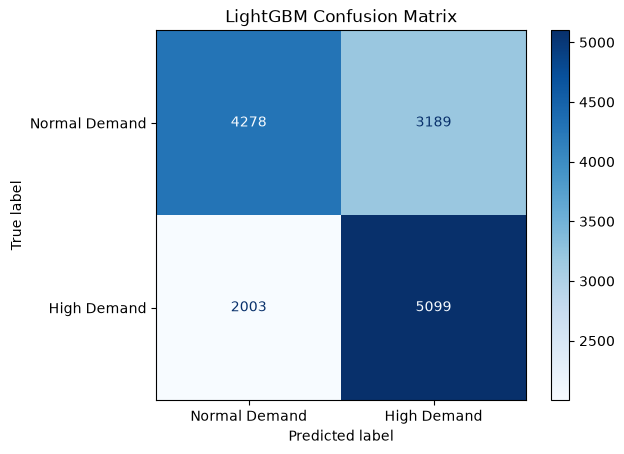

True Negative : 4278
False Positive: 3189
False Negative: 2003
True Positive : 5099


In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, lgbm_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal Demand", "High Demand"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("LightGBM Confusion Matrix")
plt.show()

# Print values
print("True Negative :", cm[0, 0])
print("False Positive:", cm[0, 1])
print("False Negative:", cm[1, 0])
print("True Positive :", cm[1, 1])

## Step 15 — Check LightGBM Overfitting

In [15]:
# Predict training data
train_pred = lgbm_model.predict(X_train)

# Calculate training metrics
train_accuracy = accuracy_score(y_train, train_pred)
train_f1 = f1_score(y_train, train_pred)

# Compare training and testing
print("LightGBM Training vs Testing")
print("----------------------------")

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy :", round(lgbm_accuracy, 4))

print("Training F1-score:", round(train_f1, 4))
print("Testing F1-score :", round(lgbm_f1, 4))

LightGBM Training vs Testing
----------------------------
Training Accuracy: 0.6599
Testing Accuracy : 0.6436
Training F1-score: 0.6767
Testing F1-score : 0.6626


## Step 16 — LightGBM Feature Importance

In [16]:
import pandas as pd

# Get feature names after preprocessing
feature_names = lgbm_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance values
importance_values = lgbm_model.named_steps[
    "model"
].feature_importances_

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort features by importance
importance_df = importance_df.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

# Display top 15 features
importance_df.head(15)

,Feature,Importance
0,numerical__StartHour,554
1,numerical__Month,342
2,categorical__ChargerCompany_0,185
3,numerical__DayOfWeek,163
4,categorical__ChargerType_0,110
5,categorical__Location_market,72
6,categorical__Location_apartment,68
7,categorical__Location_resort,62
8,categorical__Location_hotel,49
9,categorical__Location_public institution,39


## Step 17 — LightGBM Classification Report

In [17]:
from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(
    y_test,
    lgbm_pred,
    target_names=["Normal Demand", "High Demand"]
)

print("LightGBM Classification Report")
print("------------------------------")
print(report)

LightGBM Classification Report
------------------------------
               precision    recall  f1-score   support

Normal Demand       0.68      0.57      0.62      7467
  High Demand       0.62      0.72      0.66      7102

     accuracy                           0.64     14569
    macro avg       0.65      0.65      0.64     14569
 weighted avg       0.65      0.64      0.64     14569



## Step 18 — Save Classification Model

In [18]:
import os
import joblib

# Create models folder
os.makedirs("models", exist_ok=True)

# Save trained LightGBM pipeline
joblib.dump(
    lgbm_model,
    "models/lightgbm_classification.pkl"
)

print("Classification model saved successfully!")

Classification model saved successfully!


## Step 19 — Save High-Demand Threshold

In [19]:
# Calculate threshold from training data only
demand_threshold = train_df["Demand"].median()

# Save threshold
joblib.dump(
    demand_threshold,
    "models/high_demand_threshold.pkl"
)

print("High-Demand Threshold:", round(demand_threshold, 2))
print("Threshold saved successfully!")

High-Demand Threshold: 14.2
Threshold saved successfully!


## Step 20 — Verify Saved Models

In [20]:
import os

# Display saved files
print("Saved Model Files:")
print("------------------")

for file in os.listdir("models"):
    print(file)

Saved Model Files:
------------------
high_demand_threshold.pkl
lightgbm_regression.pkl
lightgbm_classification.pkl
